In [1]:
import os
import socket
import sys
import torch

print("Machine:", socket.gethostname())
print("Python:", sys.executable)
print("Working directory:", os.getcwd())
print("CUDA available:", torch.cuda.is_available())

Machine: atl1-1-03-018-2-0.pace.gatech.edu
Python: /home/hice1/skim3564/scratch/envs/semantic-art/bin/python
Working directory: /storage/ice1/7/1/skim3564/semantic-art-retrieval
CUDA available: True


In [ ]:
# %pip install -r /storage/ice1/7/1/skim3564/semantic-art-retrieval/requirements.txt

In [3]:
from pathlib import Path
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = "ViT-B/32"

project_root = Path("/storage/ice1/7/1/skim3564/semantic-art-retrieval")
cache_root = project_root / "cache"
cache_root.mkdir(parents=True, exist_ok=True)

## Get Clip

In [4]:
import clip

model, preprocess = clip.load(
    checkpoint,
    device=device,
    download_root=str(cache_root),
)

model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)

/home/hice1/skim3564/scratch/envs/semantic-art/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [5]:
print("Device:", next(model.parameters()).device)
print("Training mode:", model.training)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: cuda:0
Training mode: False
Trainable parameters: 0


## Initial Test On One Example Image-Text Pair

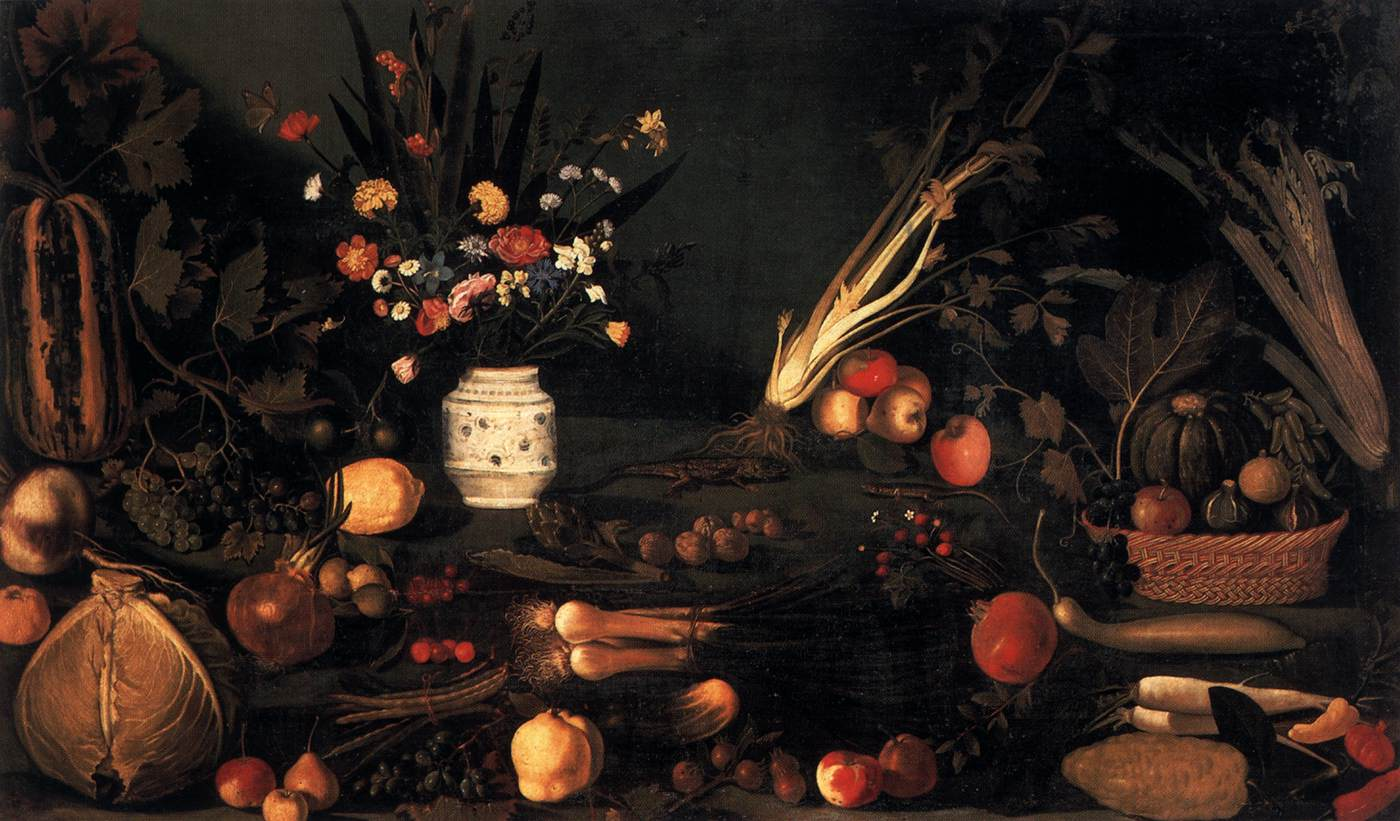

File: 07635-89d_stil.jpg
Title: Still-Life with Flowers and Fruit
Artist: CARAVAGGIO

Description: The attribution of this still-life to Caravaggio is doubtful.From a thematic point of view, large scale still-lifes in the Galleria Borghese are similar to outstanding early works by Caravaggio, but they lack the brilliance and the concentration on individual objects. This painting and another are usually attributed to Caravaggio. Because it is rather unconvincing to attribute such work to Caravaggio, some scholars distinguish this Caravaggesque painter of still-lifes from the master by naming him - after a splendid example of the genre - the Painter of the Still-Life in the Wadsworth Athenaeum, Hartford.


In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image
from IPython.display import display


project_root = Path("/storage/ice1/7/1/skim3564/semantic-art-retrieval")

semart_root = project_root / "SemArt"

df = pd.read_csv(
    semart_root / "semart_val.csv",
    sep="\t",
    encoding="cp1252",
)

row = df.iloc[0]
description = row["DESCRIPTION"]
image_path = semart_root / "Images" / row["IMAGE_FILE"]

with Image.open(image_path) as source:
    image = source.convert("RGB")

display(image)
print("File:", row["IMAGE_FILE"])
print("Title:", row["TITLE"])
print("Artist:", row["AUTHOR"])
print("\nDescription:", description)

In [19]:
val = pd.read_csv(
    semart_root / "semart_val.csv",
    sep="\t",
    encoding="cp1252",
)
train = pd.read_csv(
    semart_root / "semart_train.csv",
    sep="\t",
    encoding="cp1252",
)
test = pd.read_csv(
    semart_root / "semart_test.csv",
    sep="\t",
    encoding="cp1252",
)
df_total = pd.concat([train, test, val], axis=0, ignore_index=True)
print(df_total.shape)


(21382, 9)


In [7]:
import clip
import torch

image_input = preprocess(image).unsqueeze(0).to(device)

text_input = clip.tokenize(
    [description],
    truncate=True,
).to(device)

print("Image input:", image_input.shape)
print("Text input:", text_input.shape)

Image input: torch.Size([1, 3, 224, 224])
Text input: torch.Size([1, 77])


In [8]:
import torch.nn.functional as F

model.eval()

with torch.inference_mode():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_input).float()

    image_features = F.normalize(image_features, dim=-1)
    text_features = F.normalize(text_features, dim=-1)

    similarity = text_features @ image_features.T

print("Image embedding:", image_features.shape)
print("Text embedding:", text_features.shape)
print("Cosine similarity:", similarity.item())

Image embedding: torch.Size([1, 512])
Text embedding: torch.Size([1, 512])
Cosine similarity: 0.35360825061798096


## Batch Process

In [21]:
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

# Start with 20 pairs. Change to None for the full validation split.
NUM_EXAMPLES = None
BATCH_SIZE = 32

records = val.copy()
if NUM_EXAMPLES is not None:
    records = records.iloc[:NUM_EXAMPLES].copy()

records = records.reset_index(drop=True)

assert len(records) > 0, "No records selected."
assert records["IMAGE_FILE"].notna().all(), "Missing image filenames."
assert records["IMAGE_FILE"].is_unique, "Duplicate image filenames."
assert records["DESCRIPTION"].notna().all(), "Missing descriptions."
assert records["DESCRIPTION"].str.strip().ne("").all(), "Empty descriptions."

images_root = semart_root / "Images"

image_batches = []
text_batches = []
artwork_ids = []

model.eval()

with torch.inference_mode():
    for start in tqdm(range(0, len(records), BATCH_SIZE)):
        batch = records.iloc[start:start + BATCH_SIZE]

        # Prepare images in the same order as the descriptions.
        transformed_images = []

        for filename in batch["IMAGE_FILE"]:
            image_path = images_root / filename

            with Image.open(image_path) as source:
                image = source.convert("RGB")
                transformed_images.append(preprocess(image))

        image_input = torch.stack(transformed_images).to(device)

        text_input = clip.tokenize(
            batch["DESCRIPTION"].tolist(),
            truncate=True,
        ).to(device)

        # Encode and normalize each example independently.
        image_features = model.encode_image(image_input).float()
        text_features = model.encode_text(text_input).float()

        image_features = F.normalize(image_features, dim=-1)
        text_features = F.normalize(text_features, dim=-1)

        # Store completed embeddings on CPU to conserve GPU memory.
        image_batches.append(image_features.cpu())
        text_batches.append(text_features.cpu())
        artwork_ids.extend(batch["IMAGE_FILE"].tolist())

image_features = torch.cat(image_batches, dim=0)
text_features = torch.cat(text_batches, dim=0)

assert image_features.shape == text_features.shape
assert image_features.shape[0] == len(artwork_ids)
assert torch.isfinite(image_features).all()
assert torch.isfinite(text_features).all()

print("Image embeddings:", image_features.shape)
print("Text embeddings:", text_features.shape)
print("Artwork IDs:", len(artwork_ids))

100%|███████████████████████████████████████| 34/34 [00:35<00:00,  1.04s/it]


Image embeddings: torch.Size([1069, 512])
Text embeddings: torch.Size([1069, 512])
Artwork IDs: 1069


In [23]:
# Rows are description queries; columns are candidate paintings.
similarities = text_features @ image_features.T

# Each row contains candidate-image positions, best match first.
ranked_indices = similarities.argsort(
    dim=1,
    descending=True,
    stable=True,
)

# Preserve explicit IDs for matching rather than relying on the diagonal.
query_ids = artwork_ids.copy()
gallery_ids = artwork_ids.copy()

gallery_position = {
    artwork_id: position
    for position, artwork_id in enumerate(gallery_ids)
}

correct_columns = torch.tensor(
    [gallery_position[artwork_id] for artwork_id in query_ids],
    dtype=torch.long,
)

# Locate each correct image within its query's ranked candidate list.
correct_matches = ranked_indices == correct_columns[:, None]
assert correct_matches.sum(dim=1).eq(1).all()

# Convert zero-based positions into one-based ranks.
ranks = correct_matches.long().argmax(dim=1) + 1

metrics = {
    "num_queries": len(query_ids),
    "gallery_size": len(gallery_ids),
    "recall@1": (ranks <= 1).float().mean().item(),
    "recall@5": (ranks <= 5).float().mean().item(),
    "recall@10": (ranks <= 10).float().mean().item(),
    "mrr": ranks.float().reciprocal().mean().item(),
}

print("Similarity matrix:", similarities.shape)

for name, value in metrics.items():
    if name in {"num_queries", "gallery_size"}:
        print(f"{name}: {value}")
    else:
        print(f"{name}: {value:.4f}")

Similarity matrix: torch.Size([1069, 1069])
num_queries: 1069
gallery_size: 1069
recall@1: 0.1703
recall@5: 0.3845
recall@10: 0.4939
mrr: 0.2783


QUERY DESCRIPTION:
The attribution of this still-life to Caravaggio is doubtful.From a thematic point of view, large scale still-lifes in the Galleria Borghese are similar to outstanding early works by Caravaggio, but they lack the brilliance and the concentration on individual objects. This painting and another are usually attributed to Caravaggio. Because it is rather unconvincing to attribute such work to Caravaggio, some scholars distinguish this Caravaggesque painter of still-lifes from the master by naming him - after a splendid example of the genre - the Painter of the Still-Life in the Wadsworth Athenaeum, Hartford.

Correct painting: 07635-89d_stil.jpg
Correct painting rank: 1

Rank 1: 07635-89d_stil.jpg
Similarity: 0.3536 | Correct: True
Title: Still-Life with Flowers and Fruit
Artist: CARAVAGGIO


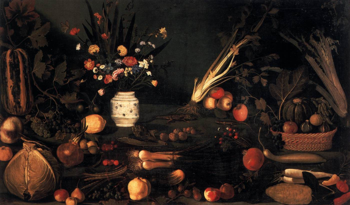

PAINTING DESCRIPTION:
The attribution of this still-life to Caravaggio is doubtful.From a thematic point of view, large scale still-lifes in the Galleria Borghese are similar to outstanding early works by Caravaggio, but they lack the brilliance and the concentration on individual objects. This painting and another are usually attributed to Caravaggio. Because it is rather unconvincing to attribute such work to Caravaggio, some scholars distinguish this Caravaggesque painter of still-lifes from the master by naming him - after a splendid example of the genre - the Painter of the Still-Life in the Wadsworth Athenaeum, Hartford.

Rank 2: 37499-stillif.jpg
Similarity: 0.3457 | Correct: False
Title: Still-Life
Artist: SNYDERS, Frans


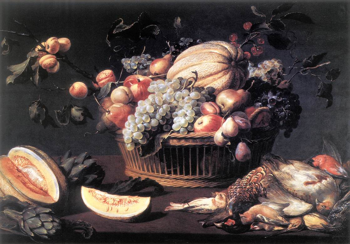

PAINTING DESCRIPTION:
Frans Snyders, Rockox's friend and neighbour and a witness to his last will and testament, was the leading still-life and animal painter of his time. His fruitful career was linked in close symbiosis with the artistic world of Rubens, with whom he frequently collaborated. Both the paintings Snyders made alone and those he produced in collaboration with Rubens are so intimately bound up with Rubens' ideas and language of form that they have to be appreciated in this context. Just as in Rubens' work, Snyders assembles the elements of his paintings not only on the basis of their artistic characteristics, but also as elements with a part to play in the overall design and decorative effect of the canvas as a whole. The luxuriant Still-Life is a representative example of Snyders' oeuvre

Rank 3: 29732-stil_lif.jpg
Similarity: 0.3362 | Correct: False
Title: Still-life with Peaches
Artist: NUVOLONE, Panfilo


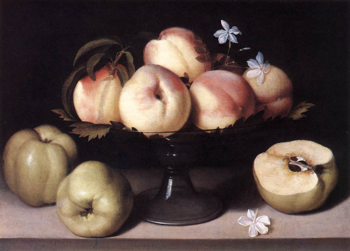

PAINTING DESCRIPTION:
Panfilo Nuvolone was one of the representatives of Lombard painting of the Counter-Reformation in Milan. His still-life contains religious symbolism corresponding to the philosophy of the Counter-Reformatrion

Rank 4: 20864-nautiluz.jpg
Similarity: 0.3299 | Correct: False
Title: Still-Life with Porcelain and a Nautilus Cup
Artist: KALF, Willem


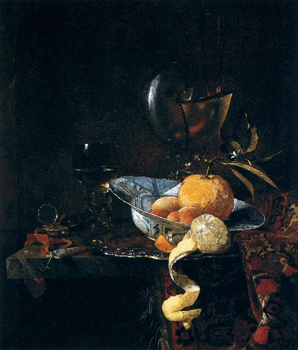

PAINTING DESCRIPTION:
The presence of the watch in this still-life might suggest the idea of the passing of time and the transience of life

Rank 5: 33312-kitchen1.jpg
Similarity: 0.3284 | Correct: False
Title: Kitchen Interior
Artist: RECCO, Giuseppe


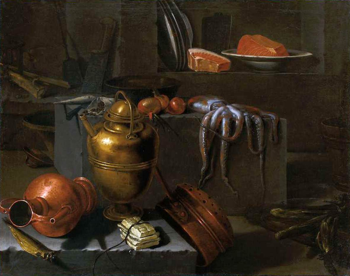

PAINTING DESCRIPTION:
The painting depicts a kitchen interior with copper ware, octopus, and onions on a stone ledge. Giuseppe Recco executed several paintings depicting kitchen interiors in the 1660s and 1670s


In [24]:
from IPython.display import display

query_index = 0
top_k = min(5, len(gallery_ids))

print("QUERY DESCRIPTION:")
print(records.iloc[query_index]["DESCRIPTION"])

print("\nCorrect painting:", query_ids[query_index])
print("Correct painting rank:", ranks[query_index].item())

for position in range(top_k):
    image_index = ranked_indices[query_index, position].item()
    filename = gallery_ids[image_index]
    score = similarities[query_index, image_index].item()
    is_correct = filename == query_ids[query_index]

    retrieved_row = records.iloc[image_index]

    print("\n" + "=" * 70)
    print(f"Rank {position + 1}: {filename}")
    print(f"Similarity: {score:.4f} | Correct: {is_correct}")
    print("Title:", retrieved_row["TITLE"])
    print("Artist:", retrieved_row["AUTHOR"])

    with Image.open(images_root / filename) as source:
        preview = source.convert("RGB")

    preview.thumbnail((350, 350))
    display(preview)

    print("PAINTING DESCRIPTION:")
    print(retrieved_row["DESCRIPTION"])

## Fine Tuning (Projection Only)

In [25]:
import json
import random
from pathlib import Path
from uuid import uuid4

import clip
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SMOKE_TEST = True  # Change to False after the small run succeeds.

config = {
    "checkpoint": "ViT-B/32",
    "batch_size": 32,
    "epochs": 1 if SMOKE_TEST else 3,
    "learning_rate": 1e-5,
    "weight_decay": 0.01,
    "seed": 42,
    "truncate": True,
    "adaptation": "projection_only",
    "smoke_test": SMOKE_TEST,
}

random.seed(config["seed"])
torch.manual_seed(config["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Connect to your ICE GPU kernel first."

project_root = Path(
    "/storage/ice1/7/1/skim3564/semantic-art-retrieval"
)
semart_root = project_root / "SemArt"
images_root = semart_root / "Images"

train_df = pd.read_csv(
    semart_root / "semart_train.csv",
    sep="\t",
    encoding="cp1252",
)
val_df = pd.read_csv(
    semart_root / "semart_val.csv",
    sep="\t",
    encoding="cp1252",
)

for frame in (train_df, val_df):
    assert frame["IMAGE_FILE"].notna().all()
    assert frame["IMAGE_FILE"].is_unique
    assert frame["DESCRIPTION"].notna().all()
    assert frame["DESCRIPTION"].str.strip().ne("").all()

assert set(train_df["IMAGE_FILE"]).isdisjoint(val_df["IMAGE_FILE"])

if SMOKE_TEST:
    train_df = train_df.sample(
        n=128, random_state=config["seed"]
    )
    val_df = val_df.sample(
        n=64, random_state=config["seed"]
    )

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

run_name = f"projection_{uuid4().hex[:8]}"
run_dir = project_root / "artifacts" / run_name
run_dir.mkdir(parents=True, exist_ok=False)

print("Device:", device)
print("Training pairs:", len(train_df))
print("Validation gallery:", len(val_df))
print("Outputs:", run_dir)

Device: cuda
Training pairs: 128
Validation gallery: 64
Outputs: /storage/ice1/7/1/skim3564/semantic-art-retrieval/artifacts/projection_febbe02f


In [26]:
finetune_model, finetune_preprocess = clip.load(
    config["checkpoint"],
    device=device,
    download_root=str(project_root / "cache"),
    jit=False,
)

# Use float32 for this straightforward training implementation.
finetune_model = finetune_model.float()

trainable_names = {"visual.proj", "text_projection"}
parameters_by_name = dict(finetune_model.named_parameters())

assert trainable_names.issubset(parameters_by_name)

for name, parameter in finetune_model.named_parameters():
    parameter.requires_grad_(name in trainable_names)

trainable_parameters = [
    parameter
    for parameter in finetune_model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"],
)

for name, parameter in finetune_model.named_parameters():
    if parameter.requires_grad:
        print(name, tuple(parameter.shape))

print(
    "Trainable parameters:",
    sum(parameter.numel() for parameter in trainable_parameters),
)

/home/hice1/skim3564/scratch/envs/semantic-art/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


text_projection (512, 512)
visual.proj (768, 512)
Trainable parameters: 655360


In [27]:
class SemArtPairs(Dataset):
    def __init__(self, frame, images_root, preprocess):
        self.frame = frame.reset_index(drop=True).copy()
        self.images_root = images_root
        self.preprocess = preprocess

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        filename = row["IMAGE_FILE"]

        with Image.open(self.images_root / filename) as source:
            image = self.preprocess(source.convert("RGB"))

        tokens = clip.tokenize(
            [row["DESCRIPTION"]],
            truncate=config["truncate"],
        )[0]

        return image, tokens, filename


train_dataset = SemArtPairs(
    train_df, images_root, finetune_preprocess
)
val_dataset = SemArtPairs(
    val_df, images_root, finetune_preprocess
)

train_loader = DataLoader(
    train_dataset,
    batch_size=config["batch_size"],
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config["batch_size"],
    shuffle=False,
    num_workers=0,
)

images, tokens, filenames = next(iter(train_loader))

print("Images:", images.shape)
print("Tokens:", tokens.shape)
print("First filename:", filenames[0])

Images: torch.Size([32, 3, 224, 224])
Tokens: torch.Size([32, 77])
First filename: 10129-20jerome.jpg


In [28]:
@torch.inference_mode()
def evaluate_retrieval(model, loader, device):
    model.eval()

    image_batches = []
    text_batches = []
    artwork_ids = []

    for images, tokens, filenames in tqdm(
        loader, desc="Validation", leave=False
    ):
        images = images.to(device)
        tokens = tokens.to(device)

        image_features = F.normalize(
            model.encode_image(images).float(), dim=-1
        )
        text_features = F.normalize(
            model.encode_text(tokens).float(), dim=-1
        )

        image_batches.append(image_features.cpu())
        text_batches.append(text_features.cpu())
        artwork_ids.extend(filenames)

    image_features = torch.cat(image_batches)
    text_features = torch.cat(text_batches)

    assert len(artwork_ids) == len(set(artwork_ids))
    assert torch.isfinite(image_features).all()
    assert torch.isfinite(text_features).all()

    similarities = text_features @ image_features.T
    ranked_indices = similarities.argsort(
        dim=1, descending=True, stable=True
    )

    # Both embedding matrices were collected from the same paired batches.
    # Query i therefore has its paired image at gallery column i.
    correct_columns = torch.arange(len(artwork_ids))
    matches = ranked_indices == correct_columns[:, None]
    ranks = matches.long().argmax(dim=1) + 1

    return {
        "num_queries": len(artwork_ids),
        "gallery_size": len(artwork_ids),
        "recall@1": (ranks <= 1).float().mean().item(),
        "recall@5": (ranks <= 5).float().mean().item(),
        "recall@10": (ranks <= 10).float().mean().item(),
        "mrr": ranks.float().reciprocal().mean().item(),
    }

In [29]:
checkpoint_path = run_dir / "best_projections.pt"


def save_projections(epoch, metrics):
    projection_weights = {
        name: parameter.detach().cpu().clone()
        for name, parameter in finetune_model.named_parameters()
        if name in trainable_names
    }

    torch.save(
        {
            "config": config,
            "epoch": epoch,
            "metrics": metrics,
            "projection_weights": projection_weights,
            "train_ids": train_df["IMAGE_FILE"].tolist(),
            "val_ids": val_df["IMAGE_FILE"].tolist(),
        },
        checkpoint_path,
    )


initial_metrics = evaluate_retrieval(
    finetune_model, val_loader, device
)

print("Before fine-tuning:", initial_metrics)

best_mrr = initial_metrics["mrr"]
save_projections(epoch=0, metrics=initial_metrics)

history = [
    {"epoch": 0, "train_loss": None, **initial_metrics}
]

with (run_dir / "config.json").open("w") as file:
    json.dump(config, file, indent=2)

Before fine-tuning: {'num_queries': 64, 'gallery_size': 64, 'recall@1': 0.5, 'recall@5': 0.875, 'recall@10': 0.9375, 'mrr': 0.6520763635635376}


In [30]:
for epoch in range(1, config["epochs"] + 1):
    # Appropriate for projection-only adaptation:
    # frozen backbone behavior stays fixed, but gradients remain enabled.
    finetune_model.eval()

    total_loss = 0.0
    examples_seen = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{config['epochs']}",
    )

    for images, tokens, filenames in progress:
        # A single pair provides no in-batch negative examples.
        if len(filenames) < 2:
            continue

        images = images.to(device)
        tokens = tokens.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Do not use inference_mode() around this training forward pass.
        image_features = F.normalize(
            finetune_model.encode_image(images).float(), dim=-1
        )
        text_features = F.normalize(
            finetune_model.encode_text(tokens).float(), dim=-1
        )

        # The pretrained logit scale stays frozen in this experiment.
        scale = finetune_model.logit_scale.exp()

        logits = scale * image_features @ text_features.T

        # Paired images and texts occupy matching batch positions.
        targets = torch.arange(images.shape[0], device=device)

        image_to_text_loss = F.cross_entropy(logits, targets)
        text_to_image_loss = F.cross_entropy(logits.T, targets)
        loss = (image_to_text_loss + text_to_image_loss) / 2

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        loss.backward()

        if examples_seen == 0:
            for name in trainable_names:
                gradient = parameters_by_name[name].grad
                assert gradient is not None, f"No gradient for {name}"
                assert torch.isfinite(gradient).all(), name

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=1.0,
            error_if_nonfinite=True,
        )
        optimizer.step()

        batch_size = images.shape[0]
        total_loss += loss.item() * batch_size
        examples_seen += batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = total_loss / examples_seen

    metrics = evaluate_retrieval(
        finetune_model, val_loader, device
    )

    epoch_result = {
        "epoch": epoch,
        "train_loss": average_loss,
        **metrics,
    }
    history.append(epoch_result)

    print(epoch_result)

    if metrics["mrr"] > best_mrr:
        best_mrr = metrics["mrr"]
        save_projections(epoch=epoch, metrics=metrics)
        print("Saved improved checkpoint.")

    with (run_dir / "history.json").open("w") as file:
        json.dump(history, file, indent=2)

Epoch 1/1: 100%|█████████████████| 4/4 [00:09<00:00,  2.30s/it, loss=1.3026]
                                                                            

{'epoch': 1, 'train_loss': 1.6584226787090302, 'num_queries': 64, 'gallery_size': 64, 'recall@1': 0.515625, 'recall@5': 0.875, 'recall@10': 0.9375, 'mrr': 0.6597309708595276}
Saved improved checkpoint.


In [31]:
saved = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

with torch.no_grad():
    for name, weights in saved["projection_weights"].items():
        parameter = parameters_by_name[name]
        parameter.copy_(
            weights.to(
                device=parameter.device,
                dtype=parameter.dtype,
            )
        )

finetune_model.eval()

print("Restored epoch:", saved["epoch"])
print("Best validation metrics:", saved["metrics"])
print("Checkpoint:", checkpoint_path)

Restored epoch: 1
Best validation metrics: {'num_queries': 64, 'gallery_size': 64, 'recall@1': 0.515625, 'recall@5': 0.875, 'recall@10': 0.9375, 'mrr': 0.6597309708595276}
Checkpoint: /storage/ice1/7/1/skim3564/semantic-art-retrieval/artifacts/projection_febbe02f/best_projections.pt
